In [1]:
import joblib, os, sys, numpy as np, pandas as pd, shap
import matplotlib.pyplot as plt
from sklearn.metrics import average_precision_score, precision_score, recall_score
from pathlib import Path

PROJECT_ROOT = Path("..")

sys.path.append(str(PROJECT_ROOT/"src"))
from explain_utils import get_shap_matrix, check_additivity   


split = joblib.load("../data/processed/fraud_train_test_split.pkl")
print(type(split))
if isinstance(split, dict):
    print(split.keys())
elif isinstance(split, (tuple, list)):
    print(len(split), [type(s).__name__ for s in split])
print(os.listdir("../models"))

<class 'tuple'>
4 ['DataFrame', 'DataFrame', 'Series', 'Series']
['fraud_lgbm_weighted.pkl', 'creditcard_logreg.pkl', 'fraud_lgbm_smote.pkl', 'fraud_logreg.pkl', 'creditcard_lgbm_smote.pkl', 'creditcard_lgbm_weighted.pkl']


In [2]:
X_train, X_test, y_train, y_test = split
model = joblib.load("../models/fraud_lgbm_weighted.pkl")

print(X_train.shape, X_test.shape)
print(y_train.shape, y_test.shape)
print("fraud rate train/test:", round(y_train.mean(), 4), round(y_test.mean(), 4))
print(type(model).__name__)

(120889, 192) (30223, 192)
(120889,) (30223,)
fraud rate train/test: 0.0936 0.0936
LGBMClassifier


In [3]:
proba = model.predict_proba(X_test)[:, 1]
pred = (proba >= 0.5).astype(int)
print(round(average_precision_score(y_test, proba), 4),
      round(precision_score(y_test, pred), 4),
      round(recall_score(y_test, pred), 4))
# expected: 0.7072 / 0.5434 / 0.6943

0.7072 0.5434 0.6943


In [4]:
print("This cell is used to predict how many times does it need to finish the whole dataset. It uses a sample of 500 from the imported dataset")
import time
explainer = shap.TreeExplainer(model)

t0 = time.time()
_ = explainer.shap_values(X_test.iloc[:500])
print(f"500 rows: {time.time() - t0:.1f}s")

This cell is used to predict how many times does it need to finish the whole dataset. It uses a sample of 500 from the imported dataset
500 rows: 0.5s


/home/avicci/fraud_detection_for_ecom_and_bank_transactions/venv/lib/python3.10/site-packages/shap/explainers/_tree.py:586: UserWarning: LightGBM binary classifier with TreeExplainer shap values output has changed to a list of ndarray
  warnings.warn(


In [5]:
sv, base = get_shap_matrix(explainer, X_test)     
print(sv.shape)                                    # expect (30223, 192)
print("base value (log-odds):", round(base, 3),
      "-> score", round(1 / (1 + np.exp(-base)), 3))

check_additivity(model, X_test, sv, base)          

np.save("../results/shap_values_ecom.npy", sv)        # adjust the folder to where you keep artifacts

/home/avicci/fraud_detection_for_ecom_and_bank_transactions/venv/lib/python3.10/site-packages/shap/explainers/_tree.py:586: UserWarning: LightGBM binary classifier with TreeExplainer shap values output has changed to a list of ndarray
  warnings.warn(


(30223, 192)
base value (log-odds): -0.609 -> score 0.352
max |raw score - (base + sum of SHAP)| = 1.08e-13


In [6]:
booster = model.booster_
feat_names = list(X_test.columns)
assert len(feat_names) == booster.num_feature()

imp = pd.DataFrame({
    "feature": feat_names,
    "gain":  booster.feature_importance(importance_type="gain"),
    "split": booster.feature_importance(importance_type="split"),
})
imp["gain_pct"]  = 100 * imp["gain"]  / imp["gain"].sum()
imp["split_pct"] = 100 * imp["split"] / imp["split"].sum()
imp = imp.sort_values("gain", ascending=False).reset_index(drop=True)

print("features never used in any split:", int((imp["split"] == 0).sum()), "of", len(imp))
print("top 10 share of total gain:", round(imp["gain_pct"].head(10).sum(), 1), "%")
imp.head(15)

features never used in any split: 103 of 192
top 10 share of total gain: 97.4 %


,feature,gain,split,gain_pct,split_pct
0,device_shared_count,882427.889058,308,63.180950,3.422222
1,time_since_signup_hours,319776.827123,1694,22.895699,18.822222
2,ip_address,38214.136208,1286,2.736094,14.288889
3,purchase_value,36701.542305,1301,2.627794,14.455556
4,hour_of_day,27425.951247,931,1.963671,10.344444
5,age,26652.614562,1008,1.908300,11.200000
6,day_of_week,14838.454346,534,1.062418,5.933333
7,source_Direct,6756.470091,163,0.483756,1.811111
8,sex_M,3718.779398,142,0.266261,1.577778
9,source_SEO,3628.021716,140,0.259763,1.555556


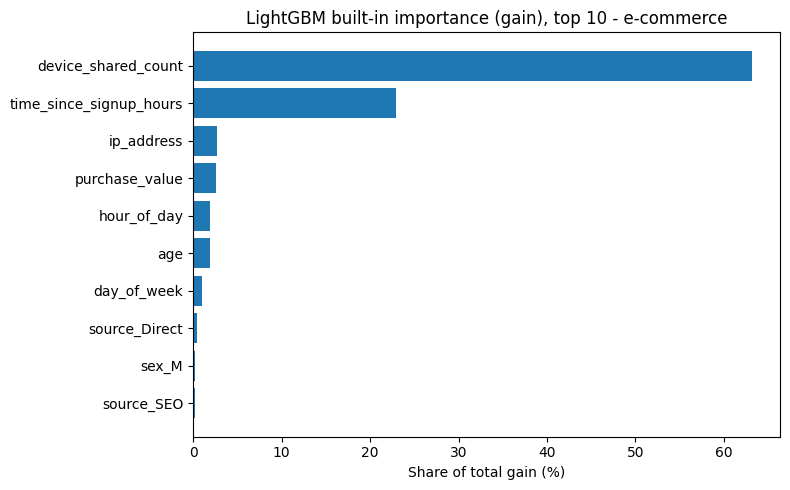

In [7]:
top10 = imp.head(10).iloc[::-1]          # reversed so the largest bar is at the top
plt.figure(figsize=(8, 5))
plt.barh(top10["feature"], top10["gain_pct"])
plt.xlabel("Share of total gain (%)")
plt.title("LightGBM built-in importance (gain), top 10 - e-commerce")
plt.tight_layout()
plt.savefig("../results/ecom_builtin_importance_top10.png", dpi=150)
plt.show()

imp.to_csv("../results/ecom_builtin_importance.csv", index=False)   # reused in block F

## Beesworm plot for SHAP

In [8]:
print("Drawing uses a 5,000-row random sample. The ranking is computed late for all of the rows")
rng = np.random.default_rng(42)
idx = rng.choice(len(X_test), size=5000, replace=False)

X_plot = X_test.iloc[idx].copy()
bool_cols = X_plot.select_dtypes(bool).columns
X_plot[bool_cols] = X_plot[bool_cols].astype("int8")   # so colors render for binary features
sv_plot = sv[idx]

print(X_plot.shape, sv_plot.shape)
print("features with any non-zero SHAP:", int((np.abs(sv).sum(axis=0) > 0).sum()), "of", sv.shape[1])

Drawing uses a 5,000-row random sample. The ranking is computed late for all of the rows
(5000, 192) (5000, 192)
features with any non-zero SHAP: 89 of 192


This cell here now checks whether this output of SHAP will be accepted on how we said there are 89 of the features from 192 have a SHAP value of >0 


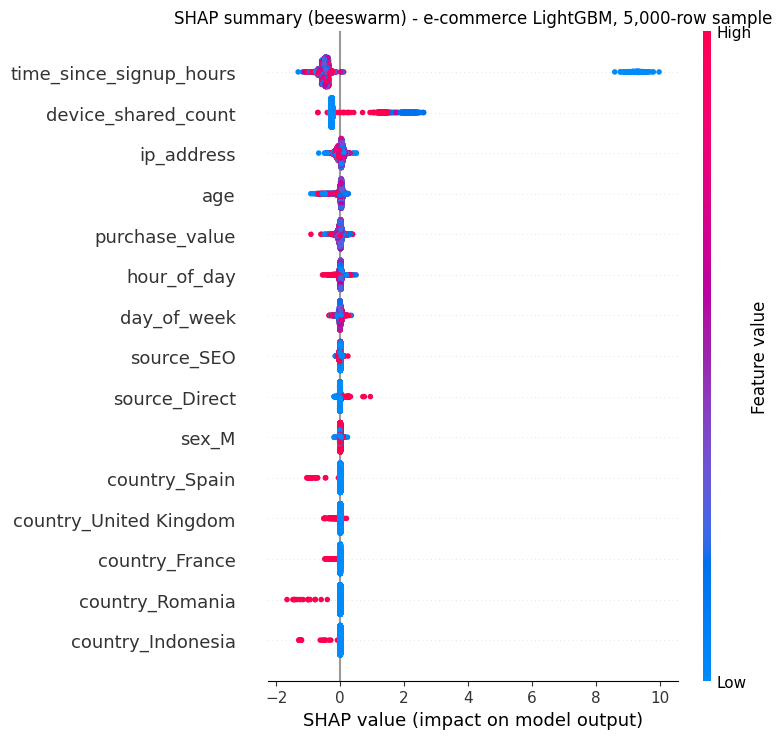

In [9]:
print("This cell here now checks whether this output of SHAP will be accepted on how we said there are 89 of the features from 192 have a SHAP value of >0 ")

shap.summary_plot(sv_plot, X_plot, max_display=15, show=False)
plt.title("SHAP summary (beeswarm) - e-commerce LightGBM, 5,000-row sample")
plt.tight_layout()
plt.savefig("../results/ecom_shap_beeswarm.png", dpi=150, bbox_inches="tight")
plt.show()

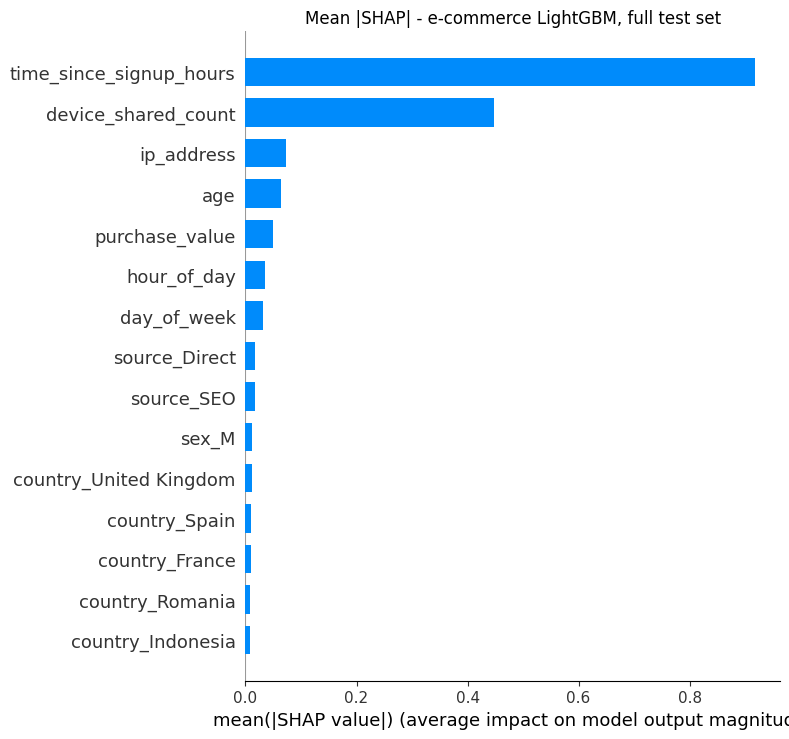

In [10]:
shap.summary_plot(sv, X_test, plot_type="bar", max_display=15, show=False)
plt.title("Mean |SHAP| - e-commerce LightGBM, full test set")
plt.tight_layout()
plt.savefig("../results/ecom_shap_bar.png", dpi=150, bbox_inches="tight")
plt.show()

In [11]:
print("Importance Table for E-com dataset")
fraud_mask = (y_test.values == 1)
abs_sv = np.abs(sv)

shap_imp = pd.DataFrame({
    "feature": X_test.columns,
    "mean_abs_shap": abs_sv.mean(axis=0),
    "mean_shap": sv.mean(axis=0),                       # signed, only a rough direction hint
    "mean_abs_shap_fraud": abs_sv[fraud_mask].mean(axis=0),
    "mean_abs_shap_legit": abs_sv[~fraud_mask].mean(axis=0),
})
shap_imp["share_pct"] = 100 * shap_imp["mean_abs_shap"] / shap_imp["mean_abs_shap"].sum()
shap_imp = shap_imp.sort_values("mean_abs_shap", ascending=False).reset_index(drop=True)
shap_imp["cum_share_pct"] = shap_imp["share_pct"].cumsum()

shap_imp.to_csv("../results/ecom_shap_importance.csv", index=False)   # reused in block F
shap_imp.head(15).round(3)

Importance Table for E-com dataset


,feature,mean_abs_shap,mean_shap,mean_abs_shap_fraud,mean_abs_shap_legit,share_pct,cum_share_pct
0,time_since_signup_hours,0.917,-0.008,5.103,0.484,51.264,51.264
1,device_shared_count,0.447,-0.011,1.161,0.373,25.001,76.265
2,ip_address,0.073,-0.001,0.054,0.075,4.109,80.373
3,age,0.064,-0.000,0.054,0.065,3.554,83.928
4,purchase_value,0.050,-0.000,0.053,0.050,2.809,86.737
5,hour_of_day,0.036,-0.000,0.029,0.036,1.997,88.733
6,day_of_week,0.032,0.000,0.031,0.032,1.799,90.532
7,source_Direct,0.017,0.001,0.030,0.015,0.935,91.467
8,source_SEO,0.016,0.000,0.014,0.017,0.919,92.386
9,sex_M,0.011,-0.000,0.010,0.011,0.609,92.994


In [12]:
print("top 5 drivers of fraud predictions")
print("The beeswarm raised two questions it couldn’t answer: what the all-blue cluster at about +9 in time_since_signup_hours is, and what the colors in the device_shared_count row mean. Settle both with numbers.")
names = list(X_test.columns)

def shap_by_value(feature):
    j = names.index(feature)
    df = pd.DataFrame({"value": X_test[feature].values,
                       "shap": sv[:, j],
                       "fraud": y_test.values})
    if df["value"].nunique() <= 15:
        key = df["value"]
    else:
        key = pd.qcut(df["value"], q=10, duplicates="drop")
    return (df.groupby(key, observed=True)
              .agg(n=("shap", "size"), mean_shap=("shap", "mean"),
                   fraud_rate=("fraud", "mean"))
              .round(3))

print(shap_by_value("device_shared_count"))

j = names.index("time_since_signup_hours")
hi = sv[:, j] > 5
print("\nrows with SHAP > 5 on time_since_signup_hours:", int(hi.sum()))
print("their feature values: min", X_test["time_since_signup_hours"][hi].min(),
      "max", X_test["time_since_signup_hours"][hi].max())
print("their fraud rate:", round(y_test[hi].mean(), 3))
print("fraud rate of all other rows:", round(y_test[~hi].mean(), 3))

top 5 drivers of fraud predictions
The beeswarm raised two questions it couldn’t answer: what the all-blue cluster at about +9 in time_since_signup_hours is, and what the colors in the device_shared_count row mean. Settle both with numbers.
                     n  mean_shap  fraud_rate
value                                        
(-0.263, 0.117]  28519     -0.088       0.046
(0.117, 6.94]     1704      1.267       0.888

rows with SHAP > 5 on time_since_signup_hours: 1484
their feature values: min -1.579065608928159 max -1.579065608928159
their fraud rate: 1.0
fraud rate of all other rows: 0.047


In [13]:
# 1. is the spike value the column minimum, and how many rows share it?
col = X_test["time_since_signup_hours"]
spike = col[hi].iloc[0]
print("column minimum equals the spike value:", np.isclose(spike, col.min()))
print("rows sharing it:", int(np.isclose(col, spike).sum()))

# 2. overlap between the two dominant signals
dev_hi = (X_test["device_shared_count"] > 0.117).values
print(pd.crosstab(hi, dev_hi, rownames=["time spike"], colnames=["device high"]))

neither = (~hi) & (~dev_hi)
print("fraud rows with neither signal:", int(y_test.values[neither].sum()),
      "of", int(y_test.sum()))

# 3. exact levels of device_shared_count (checks the colour-saturation explanation)
g = pd.DataFrame({"v": X_test["device_shared_count"].round(3),
                  "shap": sv[:, names.index("device_shared_count")],
                  "fraud": y_test.values})
print(g.groupby("v").agg(n=("shap", "size"), mean_shap=("shap", "mean"),
                         fraud_rate=("fraud", "mean")).round(3).head(12))

column minimum equals the spike value: True
rows sharing it: 1484
device high  False  True 
time spike               
False        28519    220
True             0   1484
fraud rows with neither signal: 1316 of 2830
            n  mean_shap  fraud_rate
v                                   
-0.262  26423     -0.261       0.032
 0.117   2096      2.104       0.224
 0.496     66      1.960       0.318
 0.875      2      1.910       0.500
 1.254     22      1.630       0.773
 1.633     40      1.073       0.850
 2.012     70      1.113       0.843
 2.391    108      1.293       0.926
 2.770    160      1.249       0.888
 3.149    179      1.197       0.894
 3.528    236      1.266       0.932
 3.908    206      1.262       0.927


The beeswarm listed country_Spain, country_United Kingdom, country_France and so on as separate rows, each with a tiny effect. Splitting one categorical variable into dozens of dummies makes it look unimportant, because its signal is spread over many small bars. `Grouping` puts the country signal back together.

In [14]:
prefixes = ("country_", "source_", "browser_", "sex_")

def group_of(col):
    for p in prefixes:
        if col.startswith(p):
            return p.rstrip("_")
    return col                      # numeric features stay as their own group

groups = pd.Series([group_of(c) for c in X_test.columns], index=X_test.columns)
print(groups.value_counts().head(6))

sv_df = pd.DataFrame(sv, columns=X_test.columns)
sv_grouped = sv_df.T.groupby(groups).sum().T          # shape (30223, number of groups)

nonzero = (np.abs(sv).sum(axis=0) > 0)
print("\nfeatures with non-zero SHAP, by group:")
print(pd.Series(nonzero, index=X_test.columns).groupby(groups).sum()
        .loc[lambda s: s > 0].sort_values(ascending=False))

country           178
browser             4
source              2
ip_address          1
age                 1
purchase_value      1
Name: count, dtype: int64

features with non-zero SHAP, by group:
country                    75
browser                     4
source                      2
age                         1
day_of_week                 1
hour_of_day                 1
device_shared_count         1
ip_address                  1
purchase_value              1
sex                         1
time_since_signup_hours     1
dtype: int64


In [15]:
# additivity must survive grouping
assert np.allclose(sv_grouped.sum(axis=1), sv.sum(axis=1)), "grouping broke additivity"
print("additivity holds after grouping")

abs_g = np.abs(sv_grouped.values)
grp_imp = pd.DataFrame({
    "group": sv_grouped.columns,
    "mean_abs_shap": abs_g.mean(axis=0),
    "mean_abs_shap_fraud": abs_g[fraud_mask].mean(axis=0),
    "mean_abs_shap_legit": abs_g[~fraud_mask].mean(axis=0),
})
grp_imp["share_pct"] = 100 * grp_imp["mean_abs_shap"] / grp_imp["mean_abs_shap"].sum()
grp_imp = grp_imp.sort_values("mean_abs_shap", ascending=False).reset_index(drop=True)
grp_imp.to_csv("../results/ecom_shap_importance_grouped.csv", index=False)
grp_imp.head(12).round(3)

additivity holds after grouping


,group,mean_abs_shap,mean_abs_shap_fraud,mean_abs_shap_legit,share_pct
0,time_since_signup_hours,0.917,5.103,0.484,52.548
1,device_shared_count,0.447,1.161,0.373,25.627
2,country,0.074,0.061,0.075,4.232
3,ip_address,0.073,0.054,0.075,4.211
4,age,0.064,0.054,0.065,3.643
5,purchase_value,0.050,0.053,0.050,2.879
6,hour_of_day,0.036,0.029,0.036,2.047
7,day_of_week,0.032,0.031,0.032,1.844
8,source,0.028,0.038,0.027,1.620
9,browser,0.013,0.012,0.013,0.725


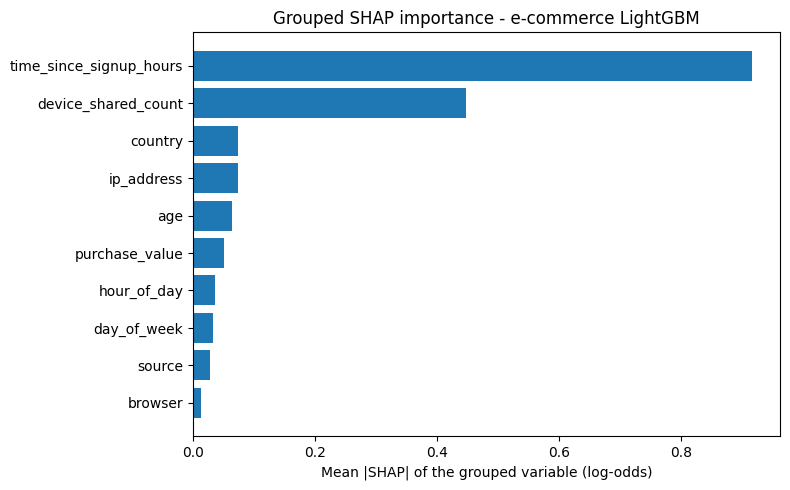

In [16]:
top = grp_imp.head(10).iloc[::-1]
plt.figure(figsize=(8, 5))
plt.barh(top["group"], top["mean_abs_shap"])
plt.xlabel("Mean |SHAP| of the grouped variable (log-odds)")
plt.title("Grouped SHAP importance - e-commerce LightGBM")
plt.tight_layout()
plt.savefig("../results/ecom_shap_grouped_bar.png", dpi=150)
plt.show()